# Patent Applications in Colombia, 2000–2021

**Who files patents in Colombia, in which fields, and how has it changed over two decades?**

## Why patents matter

A patent is a right granted by the state to an inventor or company: for a limited time,
nobody else can make, use or sell the invention without permission. In Colombia, as in the
rest of the Andean Community, an invention patent lasts 20 years and a utility model 10 years.
In exchange, the applicant must publish how the invention works, so the knowledge becomes
public and others can build on it once the protection ends.

For a country, patent applications are one of the most widely used indicators of
innovation capacity. They show where research turns into technology with commercial
value. They also show who is innovating: local universities and companies, or foreign
firms protecting their products in the Colombian market. A high share of foreign applicants
usually means that a country mostly imports technology, while a growing number of resident
applicants points to domestic research and development. Patent data also reveals which
technology sectors attract the most activity and how international agreements, such as the
Patent Cooperation Treaty (PCT), change the way inventions reach a country.

## About this analysis

This analysis answers the question above with **SQL** (MySQL) and **Python** (pandas +
matplotlib), using the **46,582 patent applications** filed at the Superintendencia de
Industria y Comercio (SIC) between 2000 and 2021.

**Workflow for each question:** question → SQL query → result table → chart (when useful) → finding.

| Chapter | Topic | Questions |
|---|---|---|
| 1 | Trends over time | 1–2 |
| 2 | Colombia and the world | 3–6 |
| 3 | Sectors and applicants | 7–9 |
| 4 | Inventors | 10–11 |

## 0. Setup

**Requirements** (run once in the terminal):
```bash
pip install pandas matplotlib sqlalchemy pymysql jupyter ipykernel
```
The database `patents` must be loaded in MySQL (see the README: `setup/patentes_a_sql.py` and
`setup/to_english.py`).

**Password:** it is never written in the notebook (the repository is public).
The notebook reads it from the environment variable `MYSQL_PASSWORD`; if it isn't set,
it asks for it when the cell runs.

In [1]:
import os
import getpass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text

USER = "cesar"
HOST = "127.0.0.1"
DATABASE = "patents"
PASSWORD = os.environ.get("MYSQL_PASSWORD") or getpass.getpass("MySQL password: ")

engine = create_engine(f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:3306/{DATABASE}")


def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return pd.read_sql(text(sql), engine)


# Quick check: rows per table
q("""
SELECT 'application' AS table_name, COUNT(*) AS n_rows FROM application UNION ALL
SELECT 'applicant',                  COUNT(*)           FROM applicant   UNION ALL
SELECT 'inventor',                   COUNT(*)           FROM inventor
""")

,table_name,n_rows
0,application,46582
1,applicant,16278
2,inventor,83230


### Chart style

Helper functions so that every chart looks the same. The colors are colorblind-safe:
use `BLUE` for a single series, and `BLUE`, `ORANGE`, `AQUA` (in that order) for two or three series.

In [2]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SOURCE = "Source: SIC, patent applications 2000–2021"
IMAGES = "../images"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11,
})


def new_ax(figsize=(9, 4.8)):
    """Create a figure with one chart."""
    return plt.subplots(figsize=figsize)


def finish(fig, ax, title, xlabel="", ylabel="", filename=None):
    """Add title, labels and source; optionally save to images/."""
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", color=INK, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.text(0.01, 0.01, SOURCE, fontsize=8, color=INK_2)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    if filename:
        os.makedirs(IMAGES, exist_ok=True)
        fig.savefig(f"{IMAGES}/{filename}", dpi=200)
    plt.show()

### The data model

| Table | Content |
|---|---|
| `application` | one row per application: `filing_date`, `type_id`, `sector_id`, `country_id`, `region`, `city`, `is_resident` |
| `application_type` | type of application, with `procedure_type` and `route` (`PCT` or `National`) |
| `sector` | technology sector (the five WIPO sectors) |
| `country` | country code and name |
| `applicant` / `application_applicant` | applicants and the N:M link (`list_order = 1` is the main applicant) |
| `inventor` / `application_inventor` | inventors and the N:M link |

`is_resident = 1` means the applicant is resident in Colombia.

---
## Chapter 1. Trends over time

### Question 1. How many patent applications were filed each year?

In [3]:
apps_year = q("""
    SELECT YEAR(filing_date) AS year,
           COUNT(*)          AS applications
    FROM application
    GROUP BY year
    ORDER BY year;
""")
apps_year

,year,applications
0,2000,1970
1,2001,670
2,2002,775
3,2003,1441
4,2004,1662
5,2005,1983
6,2006,2333
7,2007,2227
8,2008,2233
9,2009,2002


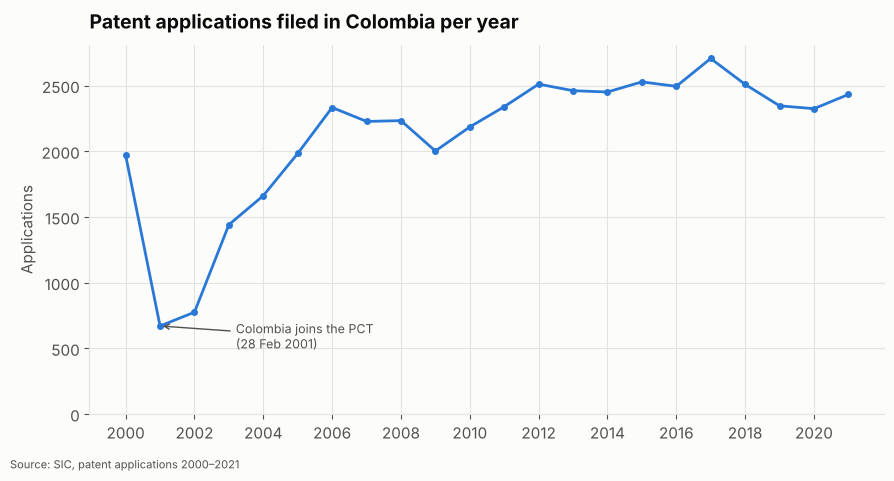

In [4]:
fig, ax = new_ax()
ax.plot(apps_year["year"], apps_year["applications"], color=BLUE, linewidth=2,
        marker="o", markersize=4)
ax.set_xticks(range(2000, 2022, 2))
ax.set_ylim(0, None)
ax.annotate("Colombia joins the PCT\n(28 Feb 2001)", xy=(2001, 670), xytext=(2003.2, 500),
            arrowprops=dict(arrowstyle="->", color=INK_2), color=INK_2, fontsize=9)
finish(fig, ax, "Patent applications filed in Colombia per year",
       ylabel="Applications", filename="q01_applications_per_year.png")

In [5]:
# Average number of applications per year, 2006-2021 (cited in the finding)
q("""
    SELECT ROUND(AVG(applications)) AS avg_per_year,
           COUNT(*)                 AS n_years
    FROM (
        SELECT YEAR(filing_date) AS year, COUNT(*) AS applications
        FROM application
        WHERE YEAR(filing_date) BETWEEN 2006 AND 2021
        GROUP BY YEAR(filing_date)
    ) AS per_year;
""")

,avg_per_year,n_years
0,2380.0,16


**Finding.** Applications fell sharply from 1,970 in 2000 to 670 in 2001. This drop coincides
with Colombia joining the **Patent Cooperation Treaty (PCT)** on 28 February 2001: as foreign
applicants moved to the PCT system, which delays entry into the national phase, filings fell
temporarily and then grew quickly from 2002 onward (see Question 2). Applications reached a
peak of **2,706 in 2017** and have stayed between 2,300 and 2,500 per year since then, with an
average of about 2,380 per year between 2006 and 2021.

The pandemic caused only a small dip in 2020 (2,324), followed by a recovery in 2021. Its full
effect may appear later, for two reasons: research disrupted in 2020 produces fewer inventions
in the following years, and PCT applications reach Colombia about 30 months after they are
first filed abroad, so most of those filed in 2020 would appear after 2021.

### Question 2. How did the share of PCT applications vs national applications change over time?

In [6]:
pct_year = q("""
    SELECT YEAR(a.filing_date) AS year,
        ROUND(100 * SUM(CASE WHEN at.route = 'National' THEN 1 ELSE 0 END) / COUNT(*), 1) AS national_pct,
        ROUND(100 * SUM(CASE WHEN at.route = 'PCT'      THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_share
    FROM application AS a
    JOIN application_type AS at ON at.type_id = a.type_id
    GROUP BY year
    ORDER BY year;
""")
pct_year

,year,national_pct,pct_share
0,2000,100.0,0.0
1,2001,99.6,0.4
2,2002,55.4,44.6
3,2003,26.4,73.6
4,2004,21.5,78.5
5,2005,21.3,78.7
6,2006,21.8,78.2
7,2007,18.3,81.7
8,2008,18.7,81.3
9,2009,20.1,79.9


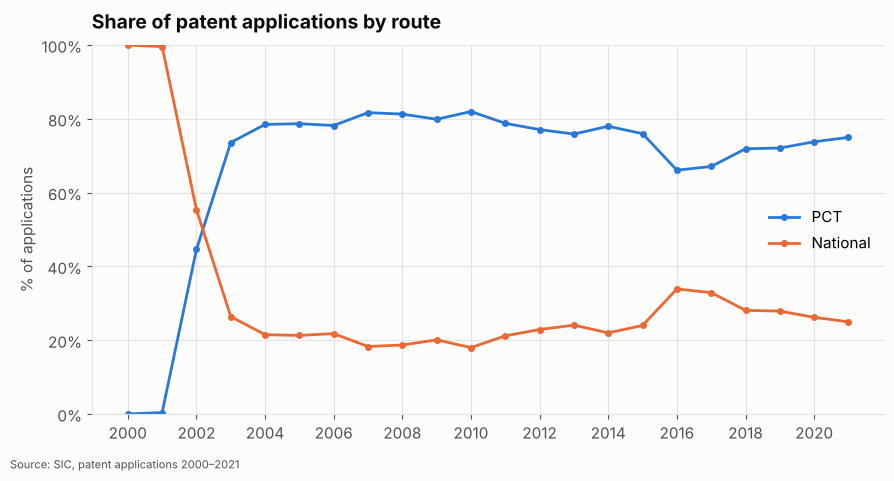

In [7]:
fig, ax = new_ax()

ax.plot(pct_year["year"], pct_year["pct_share"], color=BLUE, linewidth=2,
        marker="o", markersize=4, label="PCT")
ax.plot(pct_year["year"], pct_year["national_pct"], color=ORANGE, linewidth=2,
        marker="o", markersize=4, label="National")

ax.set_xticks(range(2000, 2022, 2))                         # one tick every 2 years
ax.set_ylim(0, 100)                                         # percentages: 0 to 100
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0f}%")    # show 20%, 40%...
ax.legend(frameon=False, loc="center right")

finish(fig, ax, "Share of patent applications by route",
    ylabel="% of applications", filename="q02_pct_share.png")

In [8]:
# Average PCT share per year since 2003 (cited in the finding)
pct_year.query("year >= 2003")[["national_pct", "pct_share"]].mean().round(1)

national_pct    23.9
pct_share       76.1
dtype: float64

In [9]:
# Counts behind the 2016 drop (cited in the finding)
q("""
    SELECT YEAR(a.filing_date)        AS year,
           SUM(at.route = 'PCT')      AS pct,
           SUM(at.route = 'National') AS national,
           SUM(a.is_resident = 1)     AS residents
    FROM application AS a
    JOIN application_type AS at ON at.type_id = a.type_id
    WHERE YEAR(a.filing_date) IN (2015, 2016)
    GROUP BY year
    ORDER BY year;
""")

,year,pct,national,residents
0,2015,1922.0,606.0,525.0
1,2016,1648.0,846.0,763.0


**Finding.** Before 2001, all applications reached Colombia through the national route. After
Colombia joined the PCT, the picture changed in only two years: PCT applications rose from
0.4% in 2001 to 44.6% in 2002 and 73.6% in 2003. From 2004 to 2015 the share was stable,
between 76% and 82%, so about four out of five applications arrived through the PCT.

In 2016 the PCT share fell to 66.1%, its lowest level since 2002, and then recovered
gradually to 75% in 2021. The 2016 drop is not only a fall in PCT filings (from 1,922 to
1,648): national applications also grew from 606 to 846, at the same time as applications
from residents rose from 525 to 763 (see Question 3). Residents usually file through the
national route, so their growth explains part of the change. Between 2003 and 2021, on
average, about 76% of applications each year came through the PCT route and 24% through the
national route.

---
## Chapter 2. Colombia and the world

### Question 3. What share of applications comes from residents of Colombia, and how has it changed?

In [10]:
residents_year = q("""
    SELECT YEAR(filing_date)                AS year,
           ROUND(100 * AVG(is_resident), 1) AS resident_pct
    FROM application
    GROUP BY year
    ORDER BY year;
""")
residents_year

,year,resident_pct
0,2000,9.4
1,2001,34.5
2,2002,32.5
3,2003,17.0
4,2004,13.4
5,2005,13.5
6,2006,15.9
7,2007,12.3
8,2008,13.8
9,2009,16.4


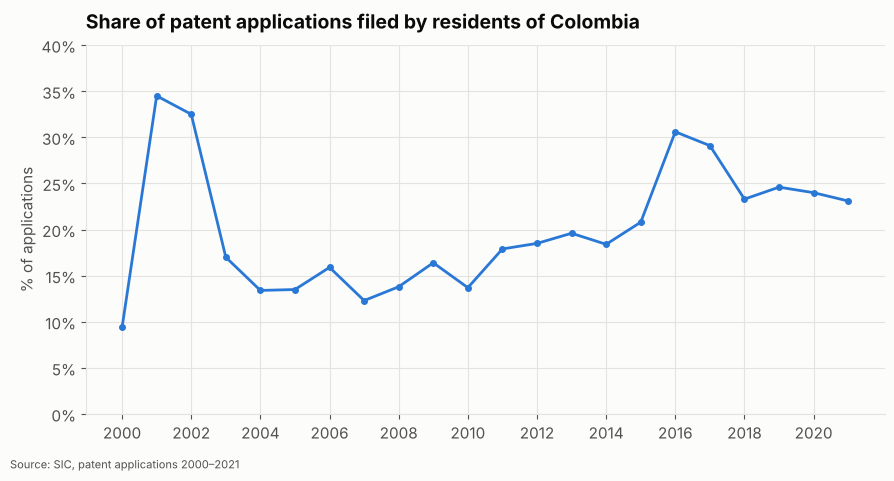

In [11]:
fig, ax = new_ax()

ax.plot(residents_year["year"], residents_year["resident_pct"], color=BLUE, linewidth=2,
        marker="o", markersize=4)

ax.set_xticks(range(2000, 2022, 2))                         # one tick every 2 years
ax.set_ylim(0, 40)                                          # start at 0, room above the max (34.5%)
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0f}%")    # show 10%, 20%...

finish(fig, ax, "Share of patent applications filed by residents of Colombia",
       ylabel="% of applications", filename="q03_resident_share.png")

**Finding.** Residents filed only 9.4% of applications in 2000. The jump to 34.5% in 2001
reflects the temporary drop in foreign filings during the PCT transition, not a boom in local
activity. Between 2003 and 2010 the share stayed at 12–17%, then rose steadily, peaking at
30.6% in 2016. Since 2018 it has held around 23–25%, roughly one in four applications.

What drives this long-term increase? Question 9 suggests one answer: the growing role of
universities.

### Question 4. Which 10 countries file the most applications in Colombia?

In [12]:
top_countries = q("""
    SELECT co.name   AS country,
           COUNT(*)  AS number_of_applications
    FROM application AS ap
    JOIN country AS co ON co.country_id = ap.country_id
    GROUP BY co.country_id, co.name
    ORDER BY number_of_applications DESC
    LIMIT 10;
""")
top_countries

,country,number_of_applications
0,United States,15126
1,Colombia,9160
2,Germany,3678
3,Switzerland,3431
4,Japan,1692
5,Sweden,1640
6,France,1610
7,United Kingdom,1228
8,Spain,1018
9,Netherlands,789


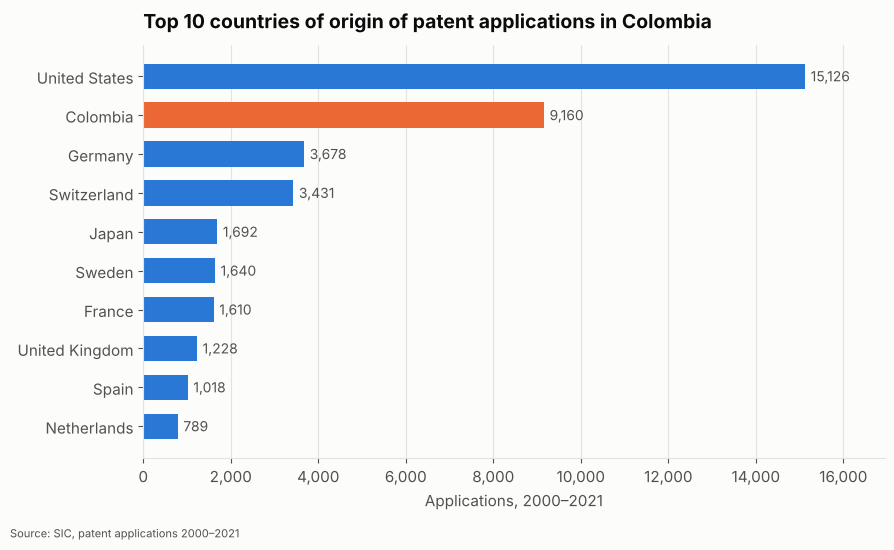

In [13]:
data = top_countries.sort_values("number_of_applications")       # barh draws bottom-up: smallest first
colors = [ORANGE if c == "Colombia" else BLUE for c in data["country"]]

fig, ax = new_ax(figsize=(9, 5.5))
bars = ax.barh(data["country"], data["number_of_applications"], color=colors, height=0.65)
ax.bar_label(bars, labels=[f"{v:,}" for v in data["number_of_applications"]],
             padding=4, fontsize=10, color=INK_2)               # value at the end of each bar

ax.grid(axis="y", visible=False)                                # keep only vertical grid lines
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")        # 2,000 instead of 2000
ax.set_xlim(0, data["number_of_applications"].max() * 1.12)    # room for the labels

finish(fig, ax, "Top 10 countries of origin of patent applications in Colombia",
       xlabel="Applications, 2000–2021", filename="q04_top_countries.png")

To compare foreign countries with each other, the next query excludes Colombia and computes each country's share of all foreign applications.

In [14]:
top_countries_pct = q("""
    SELECT c.name   AS country,
           COUNT(*) AS number_of_applications,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_foreign
    FROM application AS a
    JOIN country AS c ON c.country_id = a.country_id
    WHERE a.country_id <> 'CO'
    GROUP BY c.country_id, c.name
    ORDER BY number_of_applications DESC
    LIMIT 3;
""")
top_countries_pct

,country,number_of_applications,pct_of_foreign
0,United States,15126,40.4
1,Germany,3678,9.8
2,Switzerland,3431,9.2


**Finding.** The United States is by far the largest source of foreign patent applications in
Colombia (15,126), followed by Germany (3,678) and Switzerland (3,431). Together, these three
countries account for about **60% of all foreign applications** (40.4% for the United States
alone). A possible explanation is that large companies from these countries patent their
inventions in Colombia to protect products they sell in the local market. Which sectors and
companies are behind these applications? Questions 7 and 8 explore this.

### Question 5. What type of protection do residents and non-residents request?

In [15]:
type_protection = q("""
    WITH counts AS (                                   -- step 1: count per type of protection
        SELECT t.procedure_type,
               SUM(a.is_resident = 1) AS resident,
               SUM(a.is_resident = 0) AS non_resident
        FROM application AS a
        JOIN application_type AS t ON t.type_id = a.type_id
        GROUP BY t.procedure_type
    )
    SELECT procedure_type,                             -- step 2: divide by the column totals
           resident,
           non_resident,
           ROUND(100 * resident     / (SELECT SUM(resident)     FROM counts), 1) AS resident_pct,
           ROUND(100 * non_resident / (SELECT SUM(non_resident) FROM counts), 1) AS non_resident_pct
    FROM counts
    ORDER BY resident_pct DESC;
""")
type_protection

,procedure_type,resident,non_resident,resident_pct,non_resident_pct
0,Invention patent,5037.0,36962.0,55.0,98.8
1,Utility model,4094.0,459.0,44.7,1.2
2,Layout design,30.0,0.0,0.3,0.0


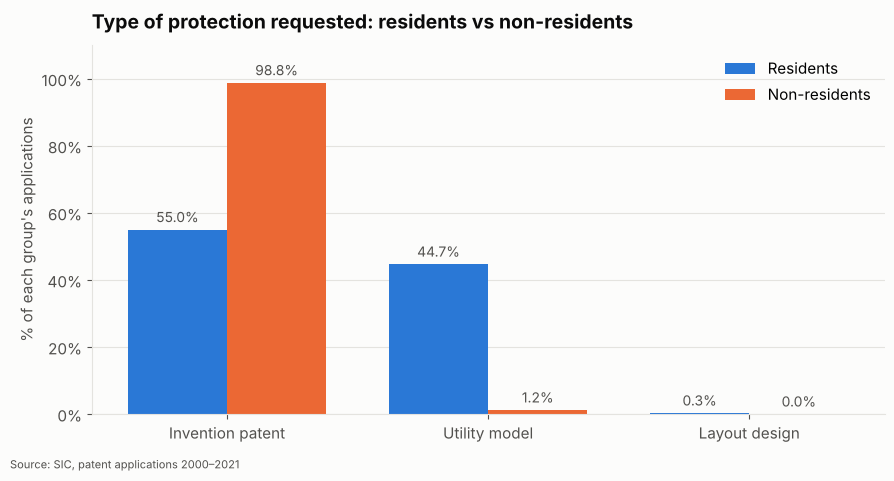

In [16]:
x = np.arange(len(type_protection))      # one position per type: 0, 1, 2
width = 0.38                             # width of each bar

fig, ax = new_ax()
b1 = ax.bar(x - width/2, type_protection["resident_pct"],     width, color=BLUE,   label="Residents")
b2 = ax.bar(x + width/2, type_protection["non_resident_pct"], width, color=ORANGE, label="Non-residents")
ax.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=10, color=INK_2)
ax.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=10, color=INK_2)

ax.set_xticks(x, type_protection["procedure_type"])
ax.set_ylim(0, 110)                                          # room for the labels above 100%
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0f}%")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right")

finish(fig, ax, "Type of protection requested: residents vs non-residents",
       ylabel="% of each group's applications", filename="q05_type_of_protection.png")

**Finding.** Colombian law offers three types of protection:

- **Invention patent:** a new product or process (20 years of protection).
- **Utility model:** a practical improvement to an existing product, such as a new shape or
  configuration that makes it work better (10 years).
- **Layout design:** the design of an integrated circuit (an electronic chip).

The results show two very different profiles. Almost all foreign applications are invention
patents (98.8%); utility models are only 1.2%. Residents, in contrast, are split almost in
half: **55.0% invention patents and 44.7% utility models** (5,037 and 4,094 applications).
Layout designs are rare: only 30 applications, all from residents.

A possible explanation is cost and scope. Protecting an invention abroad is expensive, so
foreign companies usually do it only for their most important inventions, which are invention
patents. Utility models are simpler and cheaper to obtain, which makes them attractive for
local individual inventors and small companies that improve existing products.

### Question 6. Which Colombian cities file the most applications?

In [17]:
top_cities = q("""
    SELECT city,
           COUNT(*) AS number_of_applications
    FROM application
    WHERE is_resident = 1
      AND city IS NOT NULL
    GROUP BY city
    ORDER BY number_of_applications DESC
    LIMIT 12;
""")
top_cities

,city,number_of_applications
0,"BOGOTÁ, D.C.",4316
1,MEDELLÍN,1116
2,CALI,621
3,BUCARAMANGA,304
4,BARRANQUILLA,297
5,PEREIRA,171
6,MANIZALES,169
7,ARMENIA,111
8,IBAGUÉ,107
9,CHÍA,103


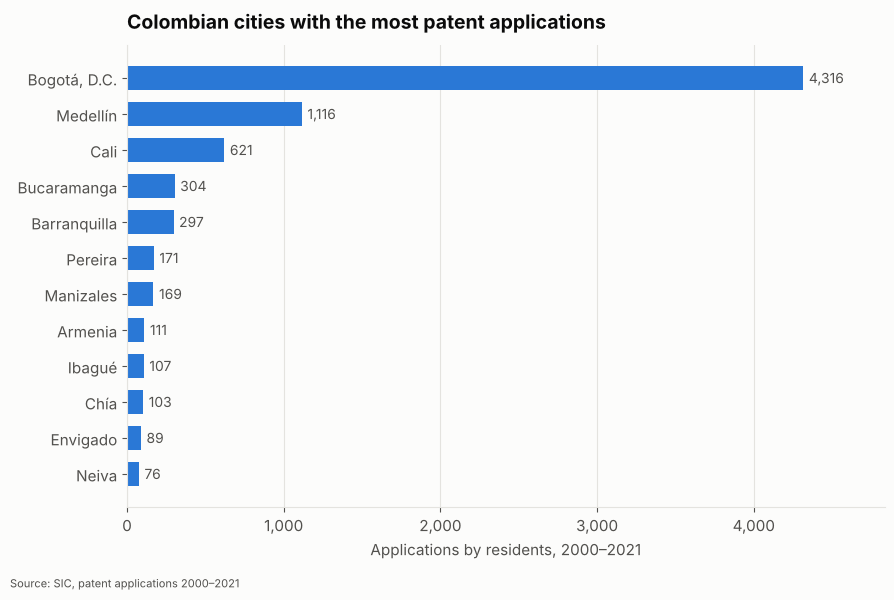

In [18]:
data = top_cities.sort_values("number_of_applications")       # smallest first → largest at the top
cities = data["city"].str.title()                              # BOGOTÁ, D.C. → Bogotá, D.C.

fig, ax = new_ax(figsize=(9, 6))
bars = ax.barh(cities, data["number_of_applications"], color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{v:,}" for v in data["number_of_applications"]],
             padding=4, fontsize=10, color=INK_2)

ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")
ax.set_xlim(0, data["number_of_applications"].max() * 1.12)

finish(fig, ax, "Colombian cities with the most patent applications",
       xlabel="Applications by residents, 2000–2021", filename="q06_top_cities.png")

**Finding.** This result is largely expected. The five cities with the most applications
(Bogotá, Medellín, Cali, Bucaramanga and Barranquilla) are also the country's main economic
centers. DANE publishes GDP (gross domestic product) by department, not by city, but the
pattern is clear: Bogotá, Antioquia and Valle del Cauca account for 25.2%, 14.8% and 9.8% of
national GDP (2024), and they lead patent activity in the same order.

Does patent activity follow the size of the regional economy? Broadly, yes, with one
exception: Bogotá alone filed about **47% of resident applications** (4,316 of 9,161), almost
twice its share of GDP. A possible reason is that many companies, universities (see Questions
8 and 9) and research institutes have their headquarters in the capital, and applications are
registered at that address.

---
## Chapter 3. Sectors and applicants

### Question 7. How do residents and non-residents differ across technology sectors?

The question is answered from two angles:

- **7a.** How are residents' and non-residents' applications distributed across sectors? (each column adds up to 100%)
- **7b.** In each sector, what share of applications comes from residents and non-residents? (each row adds up to 100%)

The 144 applications without a sector are excluded.

**7a. Distribution of each group across sectors**

In [19]:
sectors = q("""
    WITH counts AS (                                   -- step 1: count per sector
        SELECT s.name                 AS sector,
               SUM(a.is_resident = 1) AS resident,
               SUM(a.is_resident = 0) AS non_resident
        FROM application AS a
        JOIN sector AS s ON s.sector_id = a.sector_id
        GROUP BY s.name
    )
    SELECT sector,                                     -- step 2: divide by the column totals
           ROUND(100 * resident     / (SELECT SUM(resident)     FROM counts), 1) AS resident_pct,
           ROUND(100 * non_resident / (SELECT SUM(non_resident) FROM counts), 1) AS non_resident_pct
    FROM counts
    ORDER BY non_resident_pct DESC;
""")
sectors

,sector,resident_pct,non_resident_pct
0,Chemistry,21.5,66.4
1,Mechanical engineering,28.8,11.4
2,Instruments,15.2,8.8
3,Other fields,24.7,7.3
4,Electrical engineering,9.8,6.1


**7b. Residents and non-residents within each sector**

In [20]:
sectors_share = q("""
    SELECT sec.name AS sector,
           COUNT(*) AS total,
           ROUND(100 * SUM(CASE WHEN ap.is_resident = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS resident_pct,
           ROUND(100 * SUM(CASE WHEN ap.is_resident = 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS non_resident_pct
    FROM application AS ap
    JOIN sector AS sec ON sec.sector_id = ap.sector_id
    GROUP BY sector
    ORDER BY total DESC;
""")
sectors_share

,sector,total,resident_pct,non_resident_pct
0,Chemistry,26721,7.4,92.6
1,Mechanical engineering,6869,38.3,61.7
2,Other fields,4996,45.2,54.8
3,Instruments,4665,29.8,70.2
4,Electrical engineering,3187,28.2,71.8


**Finding.** Residents and non-residents file in very different sectors (7a). Residents spread
their applications fairly evenly, and no sector reaches 30% of their filings. Mechanical
engineering is the largest (28.8%), followed closely by Other fields (24.7%) and Chemistry
(21.5%). Instruments (15.2%) and Electrical engineering (9.8%) come last. Non-resident filings
are concentrated in **Chemistry, which accounts for 66.4% of their applications**, about twice
the other four sectors combined (33.6%). Each remaining sector gets only a small share, from
6.1% (Electrical engineering) to 11.4% (Mechanical engineering).

The Chemistry concentration probably reflects how multinational firms in pharmaceuticals,
agrochemicals and related industries use patents. Their products are expensive to develop but
relatively easy to copy, so patents are their main way to keep exclusive rights in a market.
Colombia's large markets for medicines and farm inputs make it worth getting that protection
here. Residents do relatively well in Mechanical engineering and Other fields (which includes
furniture, games, other consumer goods and civil engineering). This pattern fits local
individuals and small firms working in technologies that need less research spending.

Non-residents file most of the applications in every sector, but by very different margins
(7b). Chemistry is the extreme case: of its 26,721 applications, only **7.4%** come from
residents. So, although Chemistry is the third-largest sector for residents, their filings
there are dwarfed by foreign ones. This suggests that local inventive activity in chemistry,
or at least local patenting, is small compared with that of foreign firms. In the other
sectors, the non-resident share ranges from 54.8% (Other fields) to 71.8% (Electrical
engineering). Residents come closest to an even split in Other fields (45.2%) and Mechanical
engineering (38.3%), the same sectors where most of their own filings fall in 7a.

Overall, residents file roughly one in five applications with a sector (9,147 of 46,438).
As noted in Question 4, this fits the idea that foreign applicants patent in Colombia mainly
to protect products they sell in the local market, not to use inventions developed locally.

### Question 8. Who are the 10 most active foreign applicants? And the 10 most active Colombian applicants?

In [21]:
top_applicants = q("""
    SELECT ap.name,
           co.name AS country,
           COUNT(DISTINCT aa.application_id) AS number_of_applications
    FROM applicant AS ap
    JOIN application_applicant AS aa ON aa.applicant_id = ap.applicant_id
    JOIN country AS co ON co.country_id = ap.country_code
    WHERE ap.country_code <> 'CO'
    GROUP BY ap.applicant_id, ap.name, co.name
    ORDER BY number_of_applications DESC
    LIMIT 10;
""")
top_applicants

,name,country,number_of_applications
0,NOVARTIS AG,Switzerland,770
1,ESSITY HYGIENE AND HEALTH AKTIEBOLAG,Sweden,677
2,ASTRAZENECA AB,Sweden,617
3,DOW AGROSCIENCES LLC,United States,470
4,COLGATE-PALMOLIVE COMPANY,United States,462
5,WYETH LLC.,United States,348
6,BAYER PHARMA AKTIENGESELLSCHAFT,Germany,329
7,BOEHRINGER INGELHEIM INTERNATIONAL GMBH,Germany,312
8,PFIZER INC.,United States,294
9,GLAXO GROUP LIMITED,United Kingdom,268


In [22]:
top_applicants_col = q("""
    SELECT ap.name,
           COUNT(DISTINCT aa.application_id) AS number_of_applications
    FROM applicant AS ap
    JOIN application_applicant AS aa ON aa.applicant_id = ap.applicant_id
    WHERE ap.country_code = 'CO'
    GROUP BY ap.applicant_id, ap.name
    ORDER BY number_of_applications DESC
    LIMIT 10;
""")
top_applicants_col

,name,number_of_applications
0,UNIVERSIDAD NACIONAL DE COLOMBIA,192
1,ECOPETROL S.A.,186
2,UNIVERSIDAD INDUSTRIAL DE SANTANDER,97
3,UNIVERSIDAD EAFIT,77
4,UNIVERSIDAD DEL VALLE,72
5,UNIVERSIDAD DE ANTIOQUIA,69
6,UNIVERSIDAD MILITAR NUEVA GRANADA,63
7,UNIVERSIDAD DE LA SABANA,59
8,UNIVERSIDAD ANTONIO NARIÑO,56
9,UNIVERSIDAD PONTIFICIA BOLIVARIANA,46


**Finding.** The top 10 foreign applicants are large multinationals, and most work in
pharmaceuticals, agrochemicals or consumer health and personal care. Seven of the ten are
pharmaceutical companies: Novartis, AstraZeneca, Wyeth, Bayer Pharma, Boehringer Ingelheim,
Pfizer and Glaxo. Dow AgroSciences makes crop-protection products, and Colgate-Palmolive and
Essity sell oral-care and hygiene products. This explains the result of Question 7: most of
these firms patent in Chemistry, which includes pharmaceuticals, so their filings largely
account for Chemistry's 66.4% share of non-resident applications. Their products are also
sold widely in Colombia: medicines, farm inputs for an agricultural economy, and everyday
consumer goods. This supports the reading from Question 4 that foreign applicants patent in
Colombia to protect their market, not to use inventions developed here.

The United States has four of the ten (Dow AgroSciences, Colgate-Palmolive, Wyeth and Pfizer),
which fits its place as the leading filing country in Question 4. Still, the single most
active applicant is Swiss: **Novartis, with 770 applications**. Sweden (Essity, AstraZeneca)
and Germany (Bayer, Boehringer Ingelheim) each have two. A country's total comes from many
applicants, so it can lead the country ranking without having the top firm. Also, Pfizer
bought Wyeth in 2009; together, the two would have 642 applications and rank third.

The domestic ranking is led by the **Universidad Nacional de Colombia** (192), followed closely
by Ecopetrol (186), the state-controlled oil company and one of the largest companies in the
country. All the other places go to universities, so the most active Colombian applicants are
universities, not private firms. Several incentives may explain this: public-university
professors earn salary points for patents (Decreto 1279 de 2002), Minciencias' system for
ranking research groups counts patents as top-tier new-knowledge outputs, and universities and
SMEs have access to support programs and reduced filing fees. Universities therefore have
institutional reasons to patent that most Colombian companies lack, and Ecopetrol is the clear
exception. Question 9 looks at how this role has changed over time.

### Question 9. How has the role of universities in Colombian patenting changed?

Universities are identified by the text `UNIVERSI` in the name of the **main applicant**
(`list_order = 1`), which covers both *universidad* and *institución universitaria*.

In [23]:
universities_year = q("""
    SELECT YEAR(a.filing_date) AS year,
           COUNT(*)            AS resident_applications,
           SUM(ap.name LIKE '%UNIVERSI%') AS university_applications,
           ROUND(100 * AVG(ap.name LIKE '%UNIVERSI%'), 1) AS university_pct
    FROM application AS a
    JOIN application_applicant AS aa ON aa.application_id = a.application_id
                                    AND aa.list_order = 1
    JOIN applicant AS ap ON ap.applicant_id = aa.applicant_id
    WHERE a.is_resident = 1
    GROUP BY year
    ORDER BY year;
""")
universities_year

,year,resident_applications,university_applications,university_pct
0,2000,186,5.0,2.7
1,2001,231,5.0,2.2
2,2002,252,5.0,2.0
3,2003,245,11.0,4.5
4,2004,223,8.0,3.6
5,2005,268,12.0,4.5
6,2006,371,13.0,3.5
7,2007,275,10.0,3.6
8,2008,308,13.0,4.2
9,2009,329,13.0,4.0


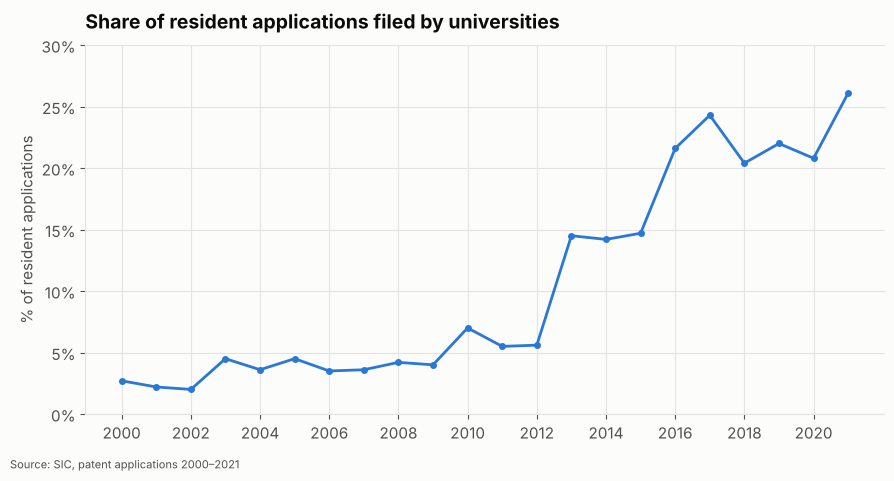

In [24]:
fig, ax = new_ax()

ax.plot(universities_year["year"], universities_year["university_pct"], color=BLUE, linewidth=2,
        marker="o", markersize=4)

ax.set_xticks(range(2000, 2022, 2))
ax.set_ylim(0, 30)
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0f}%")

finish(fig, ax, "Share of resident applications filed by universities",
       ylabel="% of resident applications", filename="q09_university_share.png")

In [25]:
# The same share by period
q("""
    SELECT CASE WHEN YEAR(a.filing_date) BETWEEN 2003 AND 2008 THEN '2003-2008'
                WHEN YEAR(a.filing_date) BETWEEN 2009 AND 2014 THEN '2009-2014'
                ELSE '2015-2021' END AS period,
           COUNT(*) AS resident_applications,
           SUM(ap.name LIKE '%UNIVERSI%') AS university_applications,
           ROUND(100 * AVG(ap.name LIKE '%UNIVERSI%'), 1) AS university_pct
    FROM application AS a
    JOIN application_applicant AS aa ON aa.application_id = a.application_id
                                    AND aa.list_order = 1
    JOIN applicant AS ap ON ap.applicant_id = aa.applicant_id
    WHERE a.is_resident = 1
      AND YEAR(a.filing_date) >= 2003
    GROUP BY period
    ORDER BY period;
""")

,period,resident_applications,university_applications,university_pct
0,2003-2008,1690,67.0,4.0
1,2009-2014,2444,217.0,8.9
2,2015-2021,4357,942.0,21.6


**Finding.** Universities have become a major source of Colombian patent applications. Until
2012 they filed less than 8% of resident applications each year. Their share jumped to about
14–15% in 2013–2015 and has stayed above 20% since 2016, reaching 26.1% in 2021. By period, it
went from **4.0% in 2003–2008** to 8.9% in 2009–2014 and **21.6% in 2015–2021**.

This helps explain the rising share of residents seen in Question 3. In 2016, for example,
university applications more than doubled (from 77 to 165), about a third of the increase in
resident applications that year (from 525 to 763). The incentives described in Question 8 are
a possible explanation, but the data alone cannot confirm the cause.

---
## Chapter 4. Inventors

### Question 10. How many inventors does an application have on average, by sector?

In [26]:
inventors_sector = q("""
WITH inventors_per_app AS (                      
    SELECT application_id, COUNT(*) AS n_inventors
    FROM application_inventor
    GROUP BY application_id
)
SELECT s.name   AS sector,
       COUNT(*) AS n_applications,
       ROUND(AVG(COALESCE(i.n_inventors, 0)), 2) AS avg_inventors
FROM application AS a
JOIN sector AS s ON s.sector_id = a.sector_id
LEFT JOIN inventors_per_app AS i ON i.application_id = a.application_id
GROUP BY s.name
ORDER BY avg_inventors DESC;
""")
inventors_sector

,sector,n_applications,avg_inventors
0,Chemistry,26721,4.47
1,Electrical engineering,3187,2.76
2,Instruments,4665,2.72
3,Mechanical engineering,6869,2.14
4,Other fields,4996,1.96


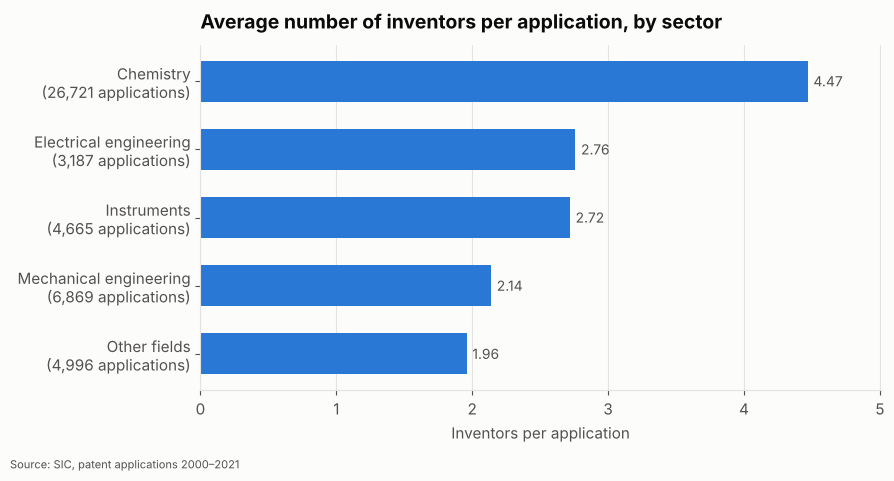

In [27]:
data = inventors_sector.sort_values("avg_inventors")            # smallest first → largest at the top
labels = [f"{s}\n({n:,} applications)"                          # name + sample size on two lines
          for s, n in zip(data["sector"], data["n_applications"])]

fig, ax = new_ax(figsize=(9, 4.8))
bars = ax.barh(labels, data["avg_inventors"], color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=10, color=INK_2)   # two decimals

ax.grid(axis="y", visible=False)
ax.set_xlim(0, data["avg_inventors"].max() * 1.12)

finish(fig, ax, "Average number of inventors per application, by sector",
       xlabel="Inventors per application", filename="q10_inventors_by_sector.png")

**Finding.** Chemistry applications list on average **4.47 inventors**, far more than any
other sector (between 1.96 and 2.76). This fits what Questions 7 and 8 showed: Chemistry is
dominated by large foreign pharmaceutical and chemical companies, whose research is done by
large teams. At the other end, Other fields (1.96) and Mechanical engineering (2.14) include
many small inventions, often developed by individuals or small groups.

### Question 11. Who are the most prolific Colombian inventors?

In [28]:
top_inventors = q("""
    SELECT inv.name,
           COUNT(DISTINCT api.application_id) AS number_of_applications
    FROM inventor AS inv
    JOIN application_inventor AS api ON api.inventor_id   = inv.inventor_id
    JOIN application          AS ap  ON ap.application_id = api.application_id
    WHERE ap.is_resident = 1
    GROUP BY inv.inventor_id, inv.name
    ORDER BY number_of_applications DESC, inv.name      -- name breaks ties
    LIMIT 10;
""")
top_inventors

,name,number_of_applications
0,PEDRO HERNAN VEGA ORTIZ,44
1,CONSTANTINO VICENTE QUINTERO HERNANDEZ,22
2,ORLANDO PLATA MURCIA,22
3,FABIO ESTEBAN REYES VÉLEZ,21
4,JOSE DAVID RENDON RIVAS,19
5,MARIO ERNESTO PEREZ GUTIERREZ,19
6,PEDRO CRISTIAN CAMARGO CARRASCAL,19
7,RAFAEL MARÍA GUTIÉRREZ SALAMANCA,19
8,WALTER ROLANDO GALVEZ RENDON,18
9,ANDRES IGNACIO HERNÁNDEZ DUARTE,17


In [29]:
# Profile of the most prolific inventor: type of protection and period
q("""
    SELECT t.procedure_type,
           COUNT(*)           AS applications,
           MIN(a.filing_date) AS first_filing,
           MAX(a.filing_date) AS last_filing
    FROM inventor AS inv
    JOIN application_inventor AS api ON api.inventor_id   = inv.inventor_id
    JOIN application          AS a   ON a.application_id  = api.application_id
    JOIN application_type     AS t   ON t.type_id         = a.type_id
    WHERE inv.name = 'PEDRO HERNAN VEGA ORTIZ'
    GROUP BY t.procedure_type;
""")

,procedure_type,applications,first_filing,last_filing
0,Invention patent,3,2007-05-04,2020-04-27
1,Utility model,41,2002-05-08,2021-11-13


In [30]:
# How many inventors of resident applications appear on only one application?
q("""
    SELECT COUNT(*)                                 AS inventors,
           SUM(n_applications = 1)                  AS with_one_application,
           ROUND(100 * AVG(n_applications = 1), 1)  AS pct_one_application
    FROM (
        SELECT api.inventor_id, COUNT(DISTINCT api.application_id) AS n_applications
        FROM application_inventor AS api
        JOIN application AS a ON a.application_id = api.application_id
        WHERE a.is_resident = 1
        GROUP BY api.inventor_id
    ) AS per_inventor;
""")

,inventors,with_one_application,pct_one_application
0,10873,8110.0,74.6


**Finding.** The most prolific Colombian inventor is **Pedro Hernán Vega Ortiz**, with 44
applications between 2002 and 2021, twice as many as the next inventors on the list (22). His
profile is unusual: he files all his applications himself, as an independent inventor, and
41 of them are utility models (practical improvements to existing products) spread across all
five technology sectors. Most of his applications list him as the only inventor. His profile
reflects two patterns seen before: the weight of utility models among residents (Question 5)
and the small teams outside Chemistry (Question 10).

He is an exception, though: of the 10,873 inventors on resident applications, 74.6% appear on
only one application. Patent activity in Colombia depends on a large number of occasional
inventors and a small group of very active ones.

---
## Final Remarks

Patent applications in Colombia grew from 670 in 2001 to a peak of 2,706 in 2017, and have
remained around 2,300–2,500 per year since then. Colombia's entry into the Patent
Cooperation Treaty (PCT) in 2001 reshaped this activity: since 2003, about three out of four
applications have arrived through the PCT route.

Most of this activity comes from abroad. The **United States** alone filed 40% of foreign
applications, and together with Germany and Switzerland, about 60%. Foreign applicants focus
on **Chemistry**, which accounts for 57.5% of all applications with a sector, and they are
mainly large pharmaceutical and chemical companies: **Novartis** is the most active applicant,
with 770 applications. These firms file almost exclusively invention patents (98.8%),
developed by large research teams (4.47 inventors per application in Chemistry).

Colombian activity has a different profile. Residents split their applications almost evenly
between invention patents (55.0%) and **utility models** (44.7%), and many are filed by
individual inventors. Their share of all applications grew from about 13% in the mid-2000s to
about 24% in recent years, driven in part by **universities**, which went from 4.0% to 21.6% of
resident applications. Activity is highly concentrated: **Bogotá** filed 47% of resident
applications, almost twice its share of national GDP.

Overall, Colombia remains mainly an importer of patented technology, but domestic patenting,
led by universities, is slowly gaining ground.

### Limitations

- The same company may appear under several spellings (e.g. `BAYER CROPSCIENCE AG` and
  `BAYER CROPSCIENCE AKTIENGESELLSCHAFT`); names were not merged automatically. City names
  have small variants too (e.g. `BOGOTÁ, D.C.` and `BOGOTA D.C.`).
- Inventors with the same name are treated as the same person (no inventor ID in the source).
- `country_id` and `is_resident` describe the **first applicant**, not the inventors.
- 144 applications have no sector and are excluded from the sector questions.
- Universities are identified by name (`LIKE '%UNIVERSI%'`); misspelled names are missed.
- GDP shares come from DANE (departmental GDP, 2024) and refer to departments, while
  Question 6 counts cities and covers 2000–2021.